<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FFishing-Zone-Prediction/notebooks/C2_fishing_zone_prediction/C2_8_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 – Notebook 8: Evaluation – does the model add value?

Run **after** Notebooks 2–6. It reads the saved test predictions (nothing in Notebooks 1–7 changes) and answers
the question examiners ask: *why use the model instead of the usual fishing grounds (Climatology)?*

| Step | Test | No GPU needed? |
|---|---|---|
| 5 | Accuracy, precision, recall, F1 (two decision rules) | ✓ |
| 6 | **Unusual days** and **new areas** – where Climatology is weak | ✓ |
| 7 | **Uncertainty check** – are errors larger where the model is unsure? | ✓ |
| 8 | Skill by **monsoon season** | ✓ |
| 9 | **Ablation** – retrain without each input (optional, ~30–60 min, GPU) | GPU |
| 10 | Value summary for the report | ✓ |

Steps 1–8 and 10 take a few minutes. Step 9 is optional and resumable.
All results are saved to `results/eval_*.csv` and `results/eval_*.png`.

## Step 1 – Connect Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
BASE = '/content/drive/MyDrive/C2_data'
CKPT_ROOT = f'{BASE}/checkpoints'; os.makedirs(CKPT_ROOT, exist_ok=True)
OUT = f'{BASE}/results';           os.makedirs(OUT, exist_ok=True)
LOCAL_CUBE = '/content/datacube_0p25.nc'
if not os.path.exists(LOCAL_CUBE):                 # copy once to Colab's fast disk (much quicker than reading Drive)
    shutil.copy(f'{BASE}/datacube_0p25.nc', LOCAL_CUBE)
print('Datacube ready:', LOCAL_CUBE)

Mounted at /content/drive
Datacube ready: /content/datacube_0p25.nc


## Step 2 – Settings (same as the model notebooks)

In [2]:
import numpy as np, pandas as pd, xarray as xr, time, json, pickle, copy
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '(turn on the T4 GPU if this says cpu)')
torch.manual_seed(42); np.random.seed(42)

# ---- same for EVERY model (fair comparison) ----
T_IN, LEADS = 7, 3                     # 7 input days (ending yesterday) -> Day 1, Day 2, Day 3
# GFW coverage in this area rose sharply Dec 2021 - early 2022 (0.5% -> 7-14% fishing cells),
# so labels before Mar 2022 are not comparable: they are used ONLY for pre-training (below).
TRAIN    = ('2022-03-01', '2023-12-31')
VAL      = ('2024-01-01', '2024-12-31')
TEST     = ('2025-01-01', '2025-12-31')
PRETRAIN = ('2017-01-01', '2021-11-30')   # old low-coverage years: learn ocean patterns, then fine-tune
FEATURES = ['sst', 'sst_grad', 'log_chl', 'sla', 'u', 'v', 'cur_speed', 'mld',
            'depth', 'moon_sin', 'moon_cos', 'doy_sin', 'doy_cos',
            'fish_clim']               # usual fishing grounds (leave-one-year-out, see Step 3)

# ---- method switches (the comparison notebook reports what was used) ----
RESIDUAL     = True    # model learns CORRECTIONS on top of climatology (usual fishing grounds)
USE_PRETRAIN = False   # pre-train on PRETRAIN years, then fine-tune on TRAIN

EPOCHS, BATCH, LR, DROPOUT = 30, 16, 1e-3, 0.2
PATIENCE = 5                           # early stopping (fine-tuning / normal training)
PRE_EPOCHS, PRE_PATIENCE = 15, 3       # pre-training
FINETUNE_LR = 3e-4                     # smaller learning rate when fine-tuning a pre-trained model
MC_RUNS, CAL_RUNS = 30, 10             # MC dropout runs for test / for fitting calibration

Device: cpu (turn on the T4 GPU if this says cpu)


## Step 3 – Load the datacube

In [3]:
X = xr.open_dataset(LOCAL_CUBE).load()
days = pd.DatetimeIndex(X.time.values)
ocean = X['depth'].isel(time=0).notnull().values                   # (H, W) True = sea
label = np.nan_to_num(X['fishing'].values).astype('float32')       # (time, H, W) 1 = fishing
tr  = (days >= TRAIN[0]) & (days <= TRAIN[1])
pre = (days >= PRETRAIN[0]) & (days <= PRETRAIN[1])

# Usual fishing grounds = how often each cell was fished in this month.
#  * validation / test days: full training period
#  * training and pre-training days: LEAVE-ONE-YEAR-OUT (from the other years of the same period),
#    so the map never contains the answer for that day.
clim_m = np.stack([label[tr & (days.month == m)].mean(0) for m in range(1, 13)])     # (12, H, W)
fc = clim_m[np.asarray(days.month) - 1].copy()
def leave_one_year_out(period):
    for y in sorted(set(days[period].year)):
        other = period & (days.year != y)
        if not other.any(): continue
        other_all = label[other].mean(0)                   # fallback: other years, all months
        for m in range(1, 13):
            these = period & (days.year == y) & (days.month == m)
            if not these.any(): continue
            src = other & (days.month == m)
            fc[these] = label[src].mean(0) if src.any() else other_all
leave_one_year_out(tr); leave_one_year_out(pre)
X['fish_clim'] = (('time', 'latitude', 'longitude'), np.where(ocean, fc, np.nan).astype('float32'))

# Residual learning: the climatology of the TARGET day, as a logit offset added to the model output
pc = np.clip(fc, 1e-3, 1 - 1e-3)
OFF = np.where(ocean, np.log(pc / (1 - pc)), 0).astype('float32')

# Features -> (time, channel, H, W), normalised with TRAINING statistics only
feat = np.stack([X[v].values for v in FEATURES], axis=1).astype('float32')
mean = np.nanmean(feat[tr], axis=(0, 2, 3), keepdims=True)
std  = np.nanstd(feat[tr],  axis=(0, 2, 3), keepdims=True) + 1e-6
feat = np.nan_to_num((feat - mean) / std, nan=0.0)                 # land / gaps -> 0

NT, C, H, W = feat.shape
lat, lon = X.latitude.values, X.longitude.values
print(f'{NT} days, {C} input channels, grid {H}x{W}, sea cells {ocean.sum()}')
for nm, (a, b) in [('pretrain', PRETRAIN), ('train', TRAIN), ('val', VAL), ('test', TEST)]:
    sel = (days >= a) & (days <= b)
    print(f'Fishing rate {nm:8s} {a[:7]}..{b[:7]}:', round(float(label[sel][:, ocean].mean()), 4))
json.dump({'features': FEATURES, 'mean': mean.ravel().tolist(), 'std': std.ravel().tolist()},
          open(f'{OUT}/normalisation.json', 'w'))

3287 days, 14 input channels, grid 40x44, sea cells 1421
Fishing rate pretrain 2017-01..2021-11: 0.0045
Fishing rate train    2022-03..2023-12: 0.1127
Fishing rate val      2024-01..2024-12: 0.1387
Fishing rate test     2025-01..2025-12: 0.0725


In [4]:
def sel_ids(period, t_in=T_IN):
    first = np.arange(t_in - 1, NT - LEADS)              # t = last input day ("yesterday")
    tgt = days[first + 1]                                # Day 1 = t + 1 ("today")
    return first[(tgt >= period[0]) & (tgt <= period[1])]
idx_pre, idx_tr, idx_va, idx_te = sel_ids(PRETRAIN), sel_ids(TRAIN), sel_ids(VAL), sel_ids(TEST)
print('samples  pretrain', len(idx_pre), ' train', len(idx_tr), ' val', len(idx_va), ' test', len(idx_te))

FEAT_T, LAB_T, OFF_T = torch.from_numpy(feat), torch.from_numpy(label), torch.from_numpy(OFF)
class Windows(torch.utils.data.Dataset):
    def __init__(self, ids, t_in=T_IN): self.ids, self.t_in = ids, t_in
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        t = self.ids[i]
        return (FEAT_T[t - self.t_in + 1: t + 1], LAB_T[t + 1: t + 1 + LEADS],
                OFF_T[t + 1: t + 1 + LEADS], t)
def loader(ids, t_in=T_IN, shuffle=False):
    return torch.utils.data.DataLoader(Windows(ids, t_in), batch_size=BATCH, shuffle=shuffle, drop_last=shuffle)

def scores(prob, ids):
    # prob: (n, LEADS, H, W). Scores sea cells only. PR-AUC is the main score (fishing cells are rare).
    rows = []
    for k in range(LEADS):
        y = label[ids + 1 + k][:, ocean].ravel()
        p = np.clip(prob[:, k][:, ocean].ravel(), 1e-6, 1 - 1e-6)
        rows.append({'lead_day': k + 1, 'PR_AUC': average_precision_score(y, p),
                     'ROC_AUC': roc_auc_score(y, p), 'Brier': brier_score_loss(y, p)})
    return pd.DataFrame(rows).round(4)

samples  pretrain 1788  train 671  val 366  test 363


## Step 4 – Load the saved test predictions (+ Climatology and Persistence on the same days)

In [5]:
DEEP = {'unet': 'U-Net (space only)', 'convlstm': 'ConvLSTM (space + time)', 'convgru': 'ConvGRU (space + time)'}
ENS = 'Ensemble (average of deep models)'
raw = {}
for k, lab in DEEP.items():
    f = f'{OUT}/{k}_test_predictions.npz'
    if os.path.exists(f):
        z = np.load(f); raw[lab] = (z['mean'].astype('float32'), z['std'].astype('float32'), z['ids'])
f = f'{OUT}/ensemble_test_predictions.npz'
if os.path.exists(f):
    z = np.load(f); raw[ENS] = (z['mean'].astype('float32'), None, z['ids'])
assert raw, 'No saved test predictions found - run notebooks 3-6 first.'

# put every model on the same test days
ids = np.array(sorted(set.intersection(*[set(r[2].tolist()) for r in raw.values()])))
preds = {}
for lab, (mn, sd, i) in raw.items():
    pos = np.searchsorted(i, ids)
    preds[lab] = dict(mean=mn[pos], std=None if sd is None else sd[pos])
# baselines on the same days (computed here, nothing to load)
preds['Climatology'] = dict(mean=np.stack([np.stack([clim_m[days[t + 1 + k].month - 1] for k in range(LEADS)]) for t in ids]).astype('float32'), std=None)
preds['Persistence (upper ref.)'] = dict(mean=np.repeat(np.stack([label[t - T_IN + 1: t + 1].mean(0) for t in ids])[:, None], LEADS, 1).astype('float32'), std=None)

Y = np.stack([label[ids + 1 + k] for k in range(LEADS)], 1)          # (n, LEADS, H, W) real fishing
best_key = open(f'{OUT}/best_model.txt').read().strip() if os.path.exists(f'{OUT}/best_model.txt') else ''
BEST = ENS if best_key == 'ensemble' else DEEP.get(best_key, next(iter(raw)))
ORDER = ['Climatology'] + [m for m in [*DEEP.values(), ENS] if m in preds] + ['Persistence (upper ref.)']
print(f'{len(ids)} test days ({days[ids[0] + 1].date()} .. {days[ids[-1] + 1].date()}) | models: {ORDER}')
print('Chosen model (Notebook 6):', BEST)
def sea_flat(a, k=0): return a[:, k][:, ocean].ravel()
def prauc(y, p): return average_precision_score(y, p) if 0 < y.sum() < len(y) else np.nan

363 test days (2025-01-01 .. 2025-12-29) | models: ['Climatology', 'U-Net (space only)', 'ConvLSTM (space + time)', 'ConvGRU (space + time)', 'Ensemble (average of deep models)', 'Persistence (upper ref.)']
Chosen model (Notebook 6): Ensemble (average of deep models)


## Step 5 – Accuracy, precision, recall, F1
Two ways to turn probabilities into "fishing / no fishing":
* **probability ≥ 0.5** – strict;
* **top 10% cells per day** – how the app recommends zones to fishermen.

"Always no fishing" shows why accuracy alone is misleading (fishing cells are rare).

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
rows = []
y = sea_flat(Y).astype(int)
for lab in ORDER:
    pm = preds[lab]['mean'][:, 0][:, ocean]                              # Day 1, (days, sea cells)
    top = (pm >= np.quantile(pm, 0.9, axis=1, keepdims=True)).ravel()  # 10% most likely cells each day
    for rule, pred in [('probability >= 0.5', pm.ravel() >= 0.5), ('top 10% cells per day', top)]:
        pred = pred.astype(int)
        rows.append({'model': lab, 'rule': rule, 'Accuracy': accuracy_score(y, pred),
                     'Precision': precision_score(y, pred, zero_division=0),
                     'Recall': recall_score(y, pred, zero_division=0), 'F1': f1_score(y, pred, zero_division=0)})
rows.append({'model': 'Always "no fishing" (reference)', 'rule': '-', 'Accuracy': 1 - y.mean(),
             'Precision': 0, 'Recall': 0, 'F1': 0})
met = pd.DataFrame(rows).round(3)
print('Day 1, test 2025. Precision = when it says "fishing here", how often it is right.')
print('Recall = how many of the real fishing cells it found.\n')
print(met.to_string(index=False))
met.to_csv(f'{OUT}/eval_metrics.csv', index=False)

Day 1, test 2025. Precision = when it says "fishing here", how often it is right.
Recall = how many of the real fishing cells it found.

                            model                  rule  Accuracy  Precision  Recall    F1
                      Climatology    probability >= 0.5     0.924      0.470   0.417 0.442
                      Climatology top 10% cells per day     0.900      0.367   0.525 0.432
               U-Net (space only)    probability >= 0.5     0.928      0.506   0.303 0.379
               U-Net (space only) top 10% cells per day     0.895      0.340   0.473 0.395
          ConvLSTM (space + time)    probability >= 0.5     0.921      0.452   0.413 0.432
          ConvLSTM (space + time) top 10% cells per day     0.901      0.365   0.509 0.425
           ConvGRU (space + time)    probability >= 0.5     0.925      0.472   0.321 0.382
           ConvGRU (space + time) top 10% cells per day     0.895      0.338   0.471 0.394
Ensemble (average of deep models)    probabi

## Step 6 – Unusual days and new areas (where Climatology is weak)
* **Unusual days** – the 25% of test days whose fishing map is least similar to the usual grounds.
* **New areas** – sea cells that were rarely fished in the training period (< 2% of days).

If the model beats Climatology here, it is using **today's ocean conditions**, not just habit.

Unusual days: 91 days whose fishing map matches the usual grounds least (similarity <= 0.36).
New areas: 551 of 1421 sea cells fished on <2% of training days; real fishing there on test days: 2035 cell-days.

                                   PR-AUC all days  PR-AUC normal days  PR-AUC UNUSUAL days (25%)  PR-AUC NEW AREAS (<2% history)
model                                                                                                                            
Climatology                                 0.4184              0.4911                     0.2104                          0.0203
U-Net (space only)                          0.3839              0.4491                     0.1906                          0.0255
ConvLSTM (space + time)                     0.4108              0.4822                     0.2123                          0.0244
ConvGRU (space + time)                      0.3827              0.4436                     0.2080                          0.0235
Ensemble (a

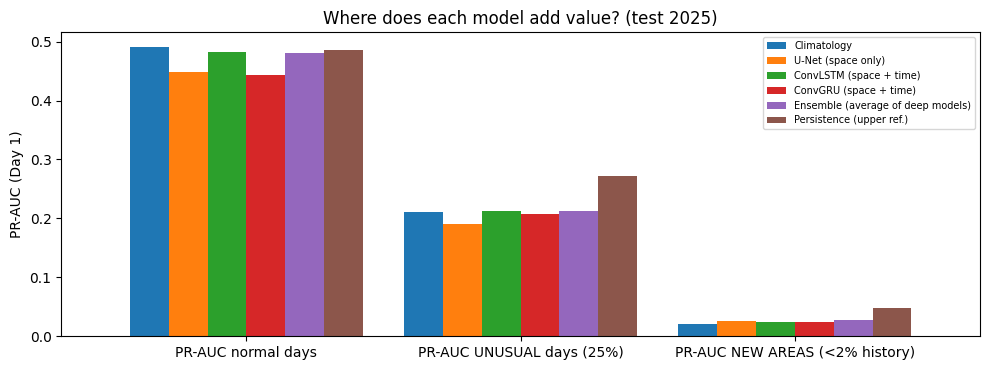

In [7]:
# ---- (a) unusual days: days whose fishing map looks least like the usual grounds ----
clim_d = preds['Climatology']['mean'][:, 0][:, ocean]; y_d = Y[:, 0][:, ocean]
def corr(a, b): return np.nan if a.std() == 0 or b.std() == 0 else np.corrcoef(a, b)[0, 1]
sim = np.array([corr(y_d[i], clim_d[i]) for i in range(len(ids))])
cut = np.nanquantile(sim, 0.25)
unusual = sim <= cut; normal = sim > cut
# ---- (b) new areas: sea cells that were rarely fished in the training period ----
hist = label[tr][:, ocean].mean(0)
LOW = 0.02
low_cells = hist < LOW
rows = []
for lab in ORDER:
    pm = preds[lab]['mean'][:, 0][:, ocean]
    rows.append({'model': lab,
                 'PR-AUC all days': prauc(y_d.ravel(), pm.ravel()),
                 'PR-AUC normal days': prauc(y_d[normal].ravel(), pm[normal].ravel()),
                 'PR-AUC UNUSUAL days (25%)': prauc(y_d[unusual].ravel(), pm[unusual].ravel()),
                 f'PR-AUC NEW AREAS (<{LOW:.0%} history)': prauc(y_d[:, low_cells].ravel(), pm[:, low_cells].ravel())})
unu = pd.DataFrame(rows).set_index('model').round(4)
print(f'Unusual days: {unusual.sum()} days whose fishing map matches the usual grounds least '
      f'(similarity <= {cut:.2f}).')
print(f'New areas: {low_cells.sum()} of {ocean.sum()} sea cells fished on <{LOW:.0%} of training days; '
      f'real fishing there on test days: {int(y_d[:, low_cells].sum())} cell-days.\n')
print(unu.to_string())
unu.to_csv(f'{OUT}/eval_unusual_and_new_areas.csv')

fig, ax = plt.subplots(figsize=(10, 3.8))
unu.drop(columns='PR-AUC all days').T.plot(kind='bar', ax=ax, width=0.85)
ax.set_ylabel('PR-AUC (Day 1)'); ax.set_title('Where does each model add value? (test 2025)')
ax.tick_params(axis='x', rotation=0); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT}/eval_unusual_and_new_areas.png', dpi=130); plt.show()

## Step 7 – Uncertainty check

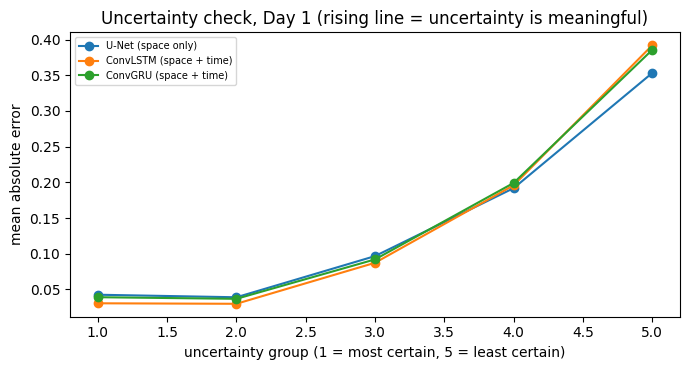

                  model  error (lowest-uncertainty 20%)  error (highest-uncertainty 20%)  correlation(uncertainty, error)
     U-Net (space only)                          0.0425                           0.3533                           0.5899
ConvLSTM (space + time)                          0.0305                           0.3921                           0.6922
 ConvGRU (space + time)                          0.0390                           0.3857                           0.6709


In [8]:
# Is the uncertainty map useful? Errors should be larger where uncertainty is higher.
withstd = [lab for lab in ORDER if preds[lab]['std'] is not None]
fig, ax = plt.subplots(figsize=(7, 3.8)); rows = []
for lab in withstd:
    p = sea_flat(preds[lab]['mean']); u = sea_flat(preds[lab]['std']); yy = sea_flat(Y)
    q = pd.qcut(u, 5, labels=False, duplicates='drop')
    g = pd.DataFrame({'q': q, 'err': np.abs(p - yy), 'u': u}).groupby('q').agg(uncertainty=('u', 'mean'), error=('err', 'mean'))
    ax.plot(range(1, len(g) + 1), g.error, 'o-', label=lab)
    rows.append({'model': lab, 'error (lowest-uncertainty 20%)': g.error.iloc[0],
                 'error (highest-uncertainty 20%)': g.error.iloc[-1],
                 'correlation(uncertainty, error)': np.corrcoef(u, np.abs(p - yy))[0, 1]})
ax.set_xlabel('uncertainty group (1 = most certain, 5 = least certain)'); ax.set_ylabel('mean absolute error')
ax.set_title('Uncertainty check, Day 1 (rising line = uncertainty is meaningful)'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT}/eval_uncertainty.png', dpi=130); plt.show()
unc = pd.DataFrame(rows).round(4); print(unc.to_string(index=False))
unc.to_csv(f'{OUT}/eval_uncertainty.csv', index=False)

## Step 8 – Skill by monsoon season

Real fishing rate per season: {'NE monsoon (Dec-Feb)': 0.069, '1st inter-monsoon (Mar-Apr)': 0.078, 'SW monsoon (May-Sep)': 0.071, '2nd inter-monsoon (Oct-Nov)': 0.074} 

                                   NE monsoon (Dec-Feb)  1st inter-monsoon (Mar-Apr)  SW monsoon (May-Sep)  2nd inter-monsoon (Oct-Nov)
model                                                                                                                                  
Climatology                                      0.2641                       0.3169                0.5550                       0.4102
U-Net (space only)                               0.2257                       0.2727                0.5241                       0.3596
ConvLSTM (space + time)                          0.2646                       0.3136                0.5452                       0.4056
ConvGRU (space + time)                           0.2476                       0.2976                0.5023                       0.3751
Ensemble (ave

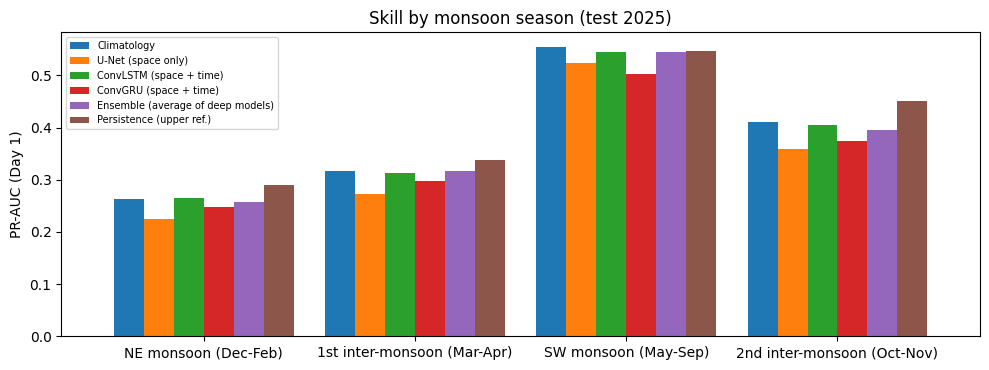

In [9]:
SEASONS = {'NE monsoon (Dec-Feb)': [12, 1, 2], '1st inter-monsoon (Mar-Apr)': [3, 4],
           'SW monsoon (May-Sep)': [5, 6, 7, 8, 9], '2nd inter-monsoon (Oct-Nov)': [10, 11]}
mon = np.asarray(days[ids + 1].month)
rows = []
for lab in ORDER:
    pm = preds[lab]['mean'][:, 0][:, ocean]
    r = {'model': lab}
    for s, ms in SEASONS.items():
        sel = np.isin(mon, ms); r[s] = prauc(y_d[sel].ravel(), pm[sel].ravel())
    rows.append(r)
sea = pd.DataFrame(rows).set_index('model').round(4)
rate = {s: round(float(y_d[np.isin(mon, ms)].mean()), 3) for s, ms in SEASONS.items()}
print('Real fishing rate per season:', rate, '\n'); print(sea.to_string())
sea.to_csv(f'{OUT}/eval_seasons.csv')
fig, ax = plt.subplots(figsize=(10, 3.8))
sea.T.plot(kind='bar', ax=ax, width=0.85)
ax.set_ylabel('PR-AUC (Day 1)'); ax.set_title('Skill by monsoon season (test 2025)')
ax.tick_params(axis='x', rotation=0); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT}/eval_seasons.png', dpi=130); plt.show()

## Step 9 – Ablation (optional, needs GPU, ~30–60 min, resumable)
Retrains the best single deep model 8 times, each time **removing** some inputs, and measures the change in
test PR-AUC. The key row is **"NO ocean conditions"**: if the score drops, the ocean data adds real skill.
For speed, ablation runs skip pre-training; compare each row with the "all inputs" row of the same table.

In [10]:
def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

class UNet(nn.Module):
    # Space only: looks at the map of the last `use_days` day(s) with no memory of how it changed.
    # Encoder shrinks the map 40x44 -> 20x22 -> 10x11 to see big patterns, decoder grows it back.
    def __init__(self, cin, p=0.2, out=3, base=32, use_days=1):
        super().__init__(); self.use_days = use_days
        self.e1 = conv_block(cin * use_days, base)
        self.e2 = conv_block(base, base * 2)
        self.mid = conv_block(base * 2, base * 4)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2); self.d2 = conv_block(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2);     self.d1 = conv_block(base * 2, base)
        self.drop = nn.Dropout2d(p)
        self.head = nn.Conv2d(base, out, 1)
    def forward(self, x):                                  # x: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        x = x[:, -self.use_days:].reshape(B, self.use_days * C, H, W)   # last day(s) stacked as channels
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        m = self.drop(self.mid(self.pool(e2)))
        d2 = self.drop(self.d2(torch.cat([self.up2(m), e2], 1)))
        d1 = self.d1(torch.cat([self.up1(d2), e1], 1))
        return self.head(self.drop(d1))

class ConvLSTMCell(nn.Module):
    def __init__(self, cin, ch, k=3):
        super().__init__(); self.ch = ch
        self.conv = nn.Conv2d(cin + ch, 4 * ch, k, padding=k // 2)
    def forward(self, x, h, c):
        i, f, o, g = torch.chunk(self.conv(torch.cat([x, h], 1)), 4, 1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        return torch.sigmoid(o) * torch.tanh(c), c

class ConvLSTMNet(nn.Module):
    # Space + time: reads the 7 days in order, remembering what it has seen (cell state)
    def __init__(self, cin, p=0.2, out=3, hidden=(32, 32)):
        super().__init__()
        self.cells = nn.ModuleList(); prev = cin
        for ch in hidden:
            self.cells.append(ConvLSTMCell(prev, ch)); prev = ch
        self.drop = nn.Dropout2d(p)
        self.head = nn.Sequential(nn.Conv2d(prev, 32, 3, padding=1), nn.ReLU(),
                                  nn.Dropout2d(p), nn.Conv2d(32, out, 1))
    def forward(self, x):                                  # x: (B, T, C, H, W)
        B, T, _, H, W = x.shape
        state = [(x.new_zeros(B, c.ch, H, W), x.new_zeros(B, c.ch, H, W)) for c in self.cells]
        for t in range(T):
            inp = x[:, t]
            for j, cell in enumerate(self.cells):
                h, c = cell(inp, *state[j]); state[j] = (h, c)
                inp = self.drop(h) if j < len(self.cells) - 1 else h
        return self.head(self.drop(inp))                   # logits (B, LEADS, H, W)

class ConvGRUCell(nn.Module):
    def __init__(self, cin, ch, k=3):
        super().__init__(); self.ch = ch
        self.gates = nn.Conv2d(cin + ch, 2 * ch, k, padding=k // 2)   # update (z) and reset (r) gates
        self.cand  = nn.Conv2d(cin + ch, ch, k, padding=k // 2)
    def forward(self, x, h):
        z, r = torch.chunk(torch.sigmoid(self.gates(torch.cat([x, h], 1))), 2, 1)
        n = torch.tanh(self.cand(torch.cat([x, r * h], 1)))
        return (1 - z) * h + z * n

class ConvGRUNet(nn.Module):
    # Space + time, like ConvLSTM but a simpler memory (no separate cell state) -> fewer parameters
    def __init__(self, cin, p=0.2, out=3, hidden=(32, 32)):
        super().__init__()
        self.cells = nn.ModuleList(); prev = cin
        for ch in hidden:
            self.cells.append(ConvGRUCell(prev, ch)); prev = ch
        self.drop = nn.Dropout2d(p)
        self.head = nn.Sequential(nn.Conv2d(prev, 32, 3, padding=1), nn.ReLU(),
                                  nn.Dropout2d(p), nn.Conv2d(32, out, 1))
    def forward(self, x):                                  # x: (B, T, C, H, W)
        B, T, _, H, W = x.shape
        state = [x.new_zeros(B, c.ch, H, W) for c in self.cells]
        for t in range(T):
            inp = x[:, t]
            for j, cell in enumerate(self.cells):
                state[j] = cell(inp, state[j])
                inp = self.drop(state[j]) if j < len(self.cells) - 1 else state[j]
        return self.head(self.drop(inp))

CLASSES = {'unet': UNet, 'convlstm': ConvLSTMNet, 'convgru': ConvGRUNet}
# Ablation uses the best SINGLE deep model (by validation PR-AUC) with its saved settings
vals = {k: pd.read_csv(f'{OUT}/{k}_val_scores.csv').PR_AUC.mean() for k in DEEP if os.path.exists(f'{OUT}/{k}_val_scores.csv')}
ABL_KEY = max(vals, key=vals.get)
ABL_CFG = json.load(open(f'{OUT}/{ABL_KEY}_config.json'))
MODEL_NAME, MODEL_LABEL, MODEL_ARGS = f'ablation_{ABL_KEY}', DEEP[ABL_KEY], ABL_CFG['model_args']
def build_model(p=DROPOUT, args=None):
    return CLASSES[ABL_KEY](C, p=p, out=LEADS, **(MODEL_ARGS if args is None else args))
print('Ablation model:', MODEL_LABEL, '| settings:', MODEL_ARGS, '| input days:', ABL_CFG['T_IN'])

Ablation model: ConvLSTM (space + time) | settings: {'hidden': [32, 32]} | input days: 7


In [11]:
CKPT = f'{CKPT_ROOT}/{MODEL_NAME}'; os.makedirs(CKPT, exist_ok=True)
mask_dev = torch.from_numpy(ocean.astype('float32')).to(DEVICE)

def pos_weight_for(period_mask):                     # extra weight for the rare fishing cells
    p = label[period_mask][:, ocean].mean()
    return torch.tensor(min((1 - p) / max(p, 1e-4), 50.0)).to(DEVICE)
PW_PRE, PW = pos_weight_for(pre), pos_weight_for(tr)
LOG_W = torch.log(PW)                                # removes the class weighting at prediction time

def masked_loss(logits, y, pw):
    l = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pw, reduction='none')
    m = mask_dev.expand_as(l)
    return (l * m).sum() / m.sum()

def logits_of(m, xb, ob):
    out = m(xb)
    return out + ob if RESIDUAL else out             # residual: climatology + learned correction

def zero_last_layer(m):
    # residual start: the untrained model outputs 0 correction = pure climatology
    last = [l for l in m.modules() if isinstance(l, nn.Conv2d)][-1]
    nn.init.zeros_(last.weight); nn.init.zeros_(last.bias)

def enable_mc(m):
    # MC dropout: dropout ON, everything else (e.g. BatchNorm) in normal prediction mode
    m.eval()
    for layer in m.modules():
        if isinstance(layer, (nn.Dropout, nn.Dropout2d)): layer.train()

@torch.no_grad()
def predict(m, dl, runs=1, calib=None):
    enable_mc(m) if runs > 1 else m.eval()
    means, stds, ids = [], [], []
    for xb, _, ob, tb in dl:
        xb, ob = xb.to(DEVICE), ob.to(DEVICE)
        ps = torch.stack([torch.sigmoid(logits_of(m, xb, ob) - LOG_W) for _ in range(runs)]).cpu().numpy()
        if calib is not None:
            for k in range(LEADS):
                ps[:, :, k] = calib[k].predict(ps[:, :, k].ravel()).reshape(ps[:, :, k].shape)
        means.append(ps.mean(0)); stds.append(ps.std(0)); ids.append(tb.numpy())
    return np.concatenate(means), np.concatenate(stds), np.concatenate(ids)

def train_stage(m, dl_train, dl_val, pw, lr, epochs, patience, tag=None, config=None, verbose=True):
    """Train with early stopping on validation PR-AUC. tag = checkpoint name (resumable), None = no files."""
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    start, best, best_ep, hist, best_state = 1, -1.0, 0, [], None
    last_f, best_f = (f'{CKPT}/{tag}_last.pt', f'{CKPT}/{tag}_best.pt') if tag else (None, None)
    if tag and os.path.exists(last_f):
        ck = torch.load(last_f, map_location=DEVICE, weights_only=False)
        if ck.get('config') == config:
            if ck.get('done'):
                m.load_state_dict(torch.load(best_f, map_location=DEVICE))
                if verbose: print(f'[{tag}] already finished (best val PR-AUC {ck["best"]:.4f}) -> loaded')
                return ck['best'], ck['best_ep'], ck['history']
            m.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
            start, best, best_ep, hist = ck['epoch'] + 1, ck['best'], ck['best_ep'], ck['history']
            if verbose: print(f'[{tag}] resuming from epoch {start}')
        elif verbose: print(f'[{tag}] settings changed -> starting again')
    for ep in range(start, epochs + 1):
        if best_ep and ep - best_ep > patience:
            if verbose: print(f'[{tag or "trial"}] early stop (best = epoch {best_ep})')
            break
        m.train(); t0 = time.time(); tot = 0
        for xb, yb, ob, _ in dl_train:
            xb, yb, ob = xb.to(DEVICE), yb.to(DEVICE), ob.to(DEVICE)
            loss = masked_loss(logits_of(m, xb, ob), yb, pw)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
            tot += loss.item()
        sched.step()
        pv, _, iv = predict(m, dl_val); pr = float(scores(pv, iv).PR_AUC.mean())
        hist.append({'epoch': ep, 'train_loss': tot / len(dl_train), 'val_PR_AUC': pr})
        improved = pr > best
        if improved:
            best, best_ep = pr, ep
            if tag: torch.save(m.state_dict(), best_f)
            else: best_state = copy.deepcopy(m.state_dict())
        if tag:
            torch.save({'model': m.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(), 'epoch': ep,
                        'best': best, 'best_ep': best_ep, 'history': hist, 'config': config}, last_f)
        if verbose:
            print(f'[{tag or "trial"}] epoch {ep:2d}/{epochs}  loss {tot/len(dl_train):.4f}  '
                  f'val PR-AUC {pr:.4f}  ({time.time()-t0:.0f}s){"  *best*" if improved else ""}')
    if tag:
        m.load_state_dict(torch.load(best_f, map_location=DEVICE))
        ck = torch.load(last_f, map_location=DEVICE, weights_only=False); ck['done'] = True; torch.save(ck, last_f)
    elif best_state is not None:
        m.load_state_dict(best_state)
    return best, best_ep, hist

def run_pipeline(t_in=T_IN, dropout=DROPOUT, lr=LR, model_args=None, pretrain=USE_PRETRAIN,
                 seed=42, save=False, verbose=True):
    """(optional) pre-train on PRETRAIN -> fine-tune / train on TRAIN, early stopping on VAL."""
    torch.manual_seed(seed); np.random.seed(seed)
    args = MODEL_ARGS if model_args is None else model_args
    m = build_model(dropout, args).to(DEVICE)
    if RESIDUAL: zero_last_layer(m)
    cfg = dict(model=MODEL_NAME, model_args=args, features=FEATURES, T_IN=t_in, LEADS=LEADS, BATCH=BATCH,
               LR=lr, DROPOUT=dropout, TRAIN=TRAIN, VAL=VAL, TEST=TEST, RESIDUAL=RESIDUAL,
               PRETRAIN=PRETRAIN if pretrain else None, FINETUNE_LR=FINETUNE_LR, seed=seed, fish_clim='loyo')
    dl_val = loader(sel_ids(VAL, t_in), t_in)
    hist = []
    if pretrain:
        _, _, h = train_stage(m, loader(sel_ids(PRETRAIN, t_in), t_in, True), dl_val, PW_PRE, lr,
                              PRE_EPOCHS, PRE_PATIENCE, 'pretrain' if save else None, cfg, verbose)
        hist += [dict(r, stage='pre-train') for r in h]
    best, best_ep, h = train_stage(m, loader(sel_ids(TRAIN, t_in), t_in, True), dl_val, PW,
                                   FINETUNE_LR if pretrain else lr, EPOCHS, PATIENCE,
                                   ('finetune' if pretrain else 'train') if save else None, cfg, verbose)
    hist += [dict(r, stage='fine-tune' if pretrain else 'train') for r in h]
    return m, best, best_ep, hist, cfg

In [ ]:
OCEAN_DYN = ['sst', 'sst_grad', 'log_chl', 'sla', 'u', 'v', 'cur_speed', 'mld']
VARIANTS = [
    ('all inputs (reference)',                         []),
    ('NO ocean conditions (grounds+depth+moon+season)', OCEAN_DYN),
    ('no usual-grounds input',                         ['fish_clim']),
    ('no SST (sst, sst_grad)',                         ['sst', 'sst_grad']),
    ('no chlorophyll',                                 ['log_chl']),
    ('no currents (u, v, speed)',                      ['u', 'v', 'cur_speed']),
    ('no sea-level anomaly',                           ['sla']),
    ('no mixed-layer depth',                           ['mld']),
]
ABL_CSV = f'{OUT}/eval_ablation_{ABL_KEY}.csv'
t_in = ABL_CFG['T_IN']
done = pd.read_csv(ABL_CSV) if os.path.exists(ABL_CSV) else pd.DataFrame(columns=['variant'])
rows = done.to_dict('records')
FEAT_FULL = FEAT_T
for name, drop in VARIANTS:
    if name in set(done.variant): print('skip (done):', name); continue
    f2 = feat.copy()
    for v in drop: f2[:, FEATURES.index(v)] = 0.0          # 0 = the average value -> no information
    FEAT_T = torch.from_numpy(f2)
    print('training:', name, '...', end=' ', flush=True)
    m, best, ep, _, _ = run_pipeline(t_in=t_in, dropout=ABL_CFG['DROPOUT'], lr=ABL_CFG['LR'], model_args=MODEL_ARGS,
                                     pretrain=False, seed=42, verbose=False)
    pt, _, it = predict(m, loader(sel_ids(TEST, t_in), t_in))
    s = scores(pt, it)
    rows.append({'variant': name, 'removed': ', '.join(drop) or '-', 'val_PR_AUC': round(best, 4),
                 'test_PR_AUC': round(float(s.PR_AUC.mean()), 4), 'test_ROC_AUC': round(float(s.ROC_AUC.mean()), 4)})
    pd.DataFrame(rows).to_csv(ABL_CSV, index=False)
    print(f'test PR-AUC {rows[-1]["test_PR_AUC"]:.4f}')
    del f2, m
FEAT_T = FEAT_FULL

abl = pd.DataFrame(rows)
ref = abl.loc[abl.variant.str.startswith('all inputs'), 'test_PR_AUC'].iloc[0]
abl['change vs all inputs'] = (abl.test_PR_AUC - ref).round(4)
print('\n', abl.to_string(index=False))
print('\nA big DROP when something is removed = that input matters.')
fig, ax = plt.subplots(figsize=(9, 0.45 * len(abl) + 1))
a2 = abl[~abl.variant.str.startswith('all inputs')].sort_values('change vs all inputs')
ax.barh(a2.variant, a2['change vs all inputs'], color=['tab:red' if c < 0 else 'tab:green' for c in a2['change vs all inputs']])
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('change in test PR-AUC when removed')
ax.set_title(f'Ablation – {MODEL_LABEL} (red = removing it hurts)')
plt.tight_layout(); plt.savefig(f'{OUT}/eval_ablation.png', dpi=130); plt.show()

training: all inputs (reference) ... test PR-AUC 0.4252
training: NO ocean conditions (grounds+depth+moon+season) ... 

## Step 10 – Value summary (for the report / viva)

In [ ]:
B = BEST
lines = []
def d(col, frame, ref='Climatology'):
    return frame.loc[B, col] - frame.loc[ref, col] if B in frame.index and ref in frame.index else np.nan
lines.append(('Overall PR-AUC (Day 1)', unu.loc[B, 'PR-AUC all days'], unu.loc['Climatology', 'PR-AUC all days']))
lines.append(('Unusual days PR-AUC', unu.loc[B, 'PR-AUC UNUSUAL days (25%)'], unu.loc['Climatology', 'PR-AUC UNUSUAL days (25%)']))
nc = [c for c in unu.columns if c.startswith('PR-AUC NEW AREAS')][0]
lines.append(('New areas PR-AUC', unu.loc[B, nc], unu.loc['Climatology', nc]))
for s in SEASONS:
    lines.append((f'{s} PR-AUC', sea.loc[B, s], sea.loc['Climatology', s]))
summ = pd.DataFrame(lines, columns=['measure', B, 'Climatology'])
summ['difference'] = (summ[B] - summ['Climatology']).round(4)
summ['model better?'] = np.where(summ.difference > 0.005, 'yes', np.where(summ.difference < -0.005, 'no', 'similar'))
print(f'VALUE SUMMARY – {B} vs Climatology (test 2025, Day 1)\n')
print(summ.round(4).to_string(index=False))
if 'abl' in globals():
    no_ocean = abl.loc[abl.variant.str.startswith('NO ocean'), 'change vs all inputs']
    if len(no_ocean): print(f'\nAblation: removing all ocean conditions changes test PR-AUC by {no_ocean.iloc[0]:+.4f} '
                            f'({"ocean data adds skill" if no_ocean.iloc[0] < -0.005 else "ocean data adds little"})')
summ.to_csv(f'{OUT}/eval_value_summary.csv', index=False)
print('\nSaved results/eval_*.csv and eval_*.png for the report.')